# Training example attention

Show the input puzzle and one 9x9 attention map per block, from a selected query cell to all 81 cells. The orange outline marks the query. There is no averaging. Attention weights describe information mixing, not causal importance.

In [20]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from datasets import Features, Value, load_dataset

SUDOKU_DIR = Path.cwd() if Path('model.py').exists() else Path.cwd() / 'Sudoku'
sys.path.insert(0, str(SUDOKU_DIR.resolve()))
from model import NeuralNetwork

MODEL_PATH = SUDOKU_DIR / 'sudoku_model.pt'
EXAMPLE_INDEX = 0  # Index in the training split (first 90% of the dataset).
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


Load the trained checkpoint and reconstruct its architecture from the saved weights.

In [21]:
checkpoint = torch.load(MODEL_PATH, map_location='cpu', weights_only=True)
state_dict = checkpoint.get('state_dict', checkpoint)
if 'input_projection.weight' not in state_dict:
    raise ValueError(
        f'{MODEL_PATH} is not a compatible attention checkpoint. '
        'The older MLP has no attention matrices. Train the current model '
        'with train.py or change MODEL_PATH to an attention checkpoint.'
    )

# Infer architecture from tensors, including checkpoints saved without metadata.
block_ids = sorted({int(key.split('.')[1]) for key in state_dict if key.startswith('blocks.')})
if not block_ids or block_ids != list(range(len(block_ids))):
    raise ValueError('Expected consecutive attention block indices starting at zero.')
if any(f'blocks.{i}.ln1.weight' not in state_dict for i in block_ids):
    raise ValueError('This checkpoint predates the current LayerNorm architecture in model.py.')
layer_sizes = [state_dict[f'blocks.{i}.mlp.0.weight'].shape[0] for i in block_ids]
net = NeuralNetwork(
    layer_sizes,
    embed_dim=state_dict['input_projection.weight'].shape[0],
    grid_size=state_dict['position_embedding.weight'].shape[0],
    n_classes=state_dict['Wo.weight'].shape[0],
)
net.load_state_dict(state_dict, strict=True)
if net.grid_size != 81 or net.n_classes != 9:
    raise ValueError('These plots require a 9x9 Sudoku model with nine output classes.')
net.to(DEVICE).eval()
print(f'Loaded {MODEL_PATH}: {len(net.blocks)} blocks, embedding dimension {net.embed_dim}')

Loaded /home/lucchi0001/work/Foundations_Deep_Learning_course_HS26/notebooks/01_MLP/Sudoku/sudoku_model.pt: 4 blocks, embedding dimension 256


Load one training puzzle and its solution using `EXAMPLE_INDEX`.

In [22]:
features = Features({'puzzle': Value('string'), 'solution': Value('string')})
dataset = load_dataset('certen/Sudoku-1M-Puzzles', features=features)['train']
n_training = int(0.9 * len(dataset))
if not 0 <= EXAMPLE_INDEX < n_training:
    raise ValueError(f'EXAMPLE_INDEX must be between 0 and {n_training - 1}.')

example = dataset[EXAMPLE_INDEX]
puzzle = torch.tensor([int(c) for c in example['puzzle']], dtype=torch.long).reshape(9, 9)
solution = torch.tensor([int(c) for c in example['solution']], dtype=torch.long).reshape(9, 9)


Choose the cell whose attention to the rest of the grid will be shown. Use `None` for the first blank cell, or specify zero-based `(row, column)` coordinates.

In [23]:
# Change the query here, then rerun this cell and the cells below.
QUERY_CELL = None  # First blank cell, or zero-based coordinates such as (4, 4).

if QUERY_CELL is None:
    blanks = torch.where(puzzle.flatten() == 0)[0]
    query = blanks[0].item() if len(blanks) else 0
else:
    if len(QUERY_CELL) != 2 or any(not isinstance(v, int) or not 0 <= v < 9 for v in QUERY_CELL):
        raise ValueError('QUERY_CELL must be a pair of integer coordinates between 0 and 8.')
    query = QUERY_CELL[0] * 9 + QUERY_CELL[1]
query_row, query_col = divmod(query, 9)


Run the model and extract the selected query's 81 attention weights from each block. Reshape each set of weights into a 9x9 grid.

In [24]:
@torch.inference_mode()
def collect_query_attention(model, puzzle, query):
    queries, keys = {}, {}
    handles = []

    def capture(destination, index):
        def hook(module, args, output):
            destination[index] = output.detach()
        return hook

    try:
        # Capture projections from the model's actual forward pass.
        for index, block in enumerate(model.blocks):
            handles.append(block.Wq.register_forward_hook(capture(queries, index)))
            handles.append(block.Wk.register_forward_hook(capture(keys, index)))
        logits = model(puzzle.reshape(1, 81).to(DEVICE))
        weights = torch.stack([
            torch.softmax(
                queries[i][:, query:query + 1] @ keys[i].transpose(-2, -1)
                / queries[i].shape[-1]**0.5, dim=-1,
            ).reshape(9, 9)
            for i in range(len(model.blocks))
        ])
        prediction = logits.argmax(dim=1).reshape(9, 9) + 1
        return prediction.cpu(), weights.cpu()
    finally:
        for handle in handles:
            handle.remove()

prediction, weights = collect_query_attention(net, puzzle, query)


Plot the input puzzle alongside the attention maps, using a shared color scale. The orange outline marks the query cell.

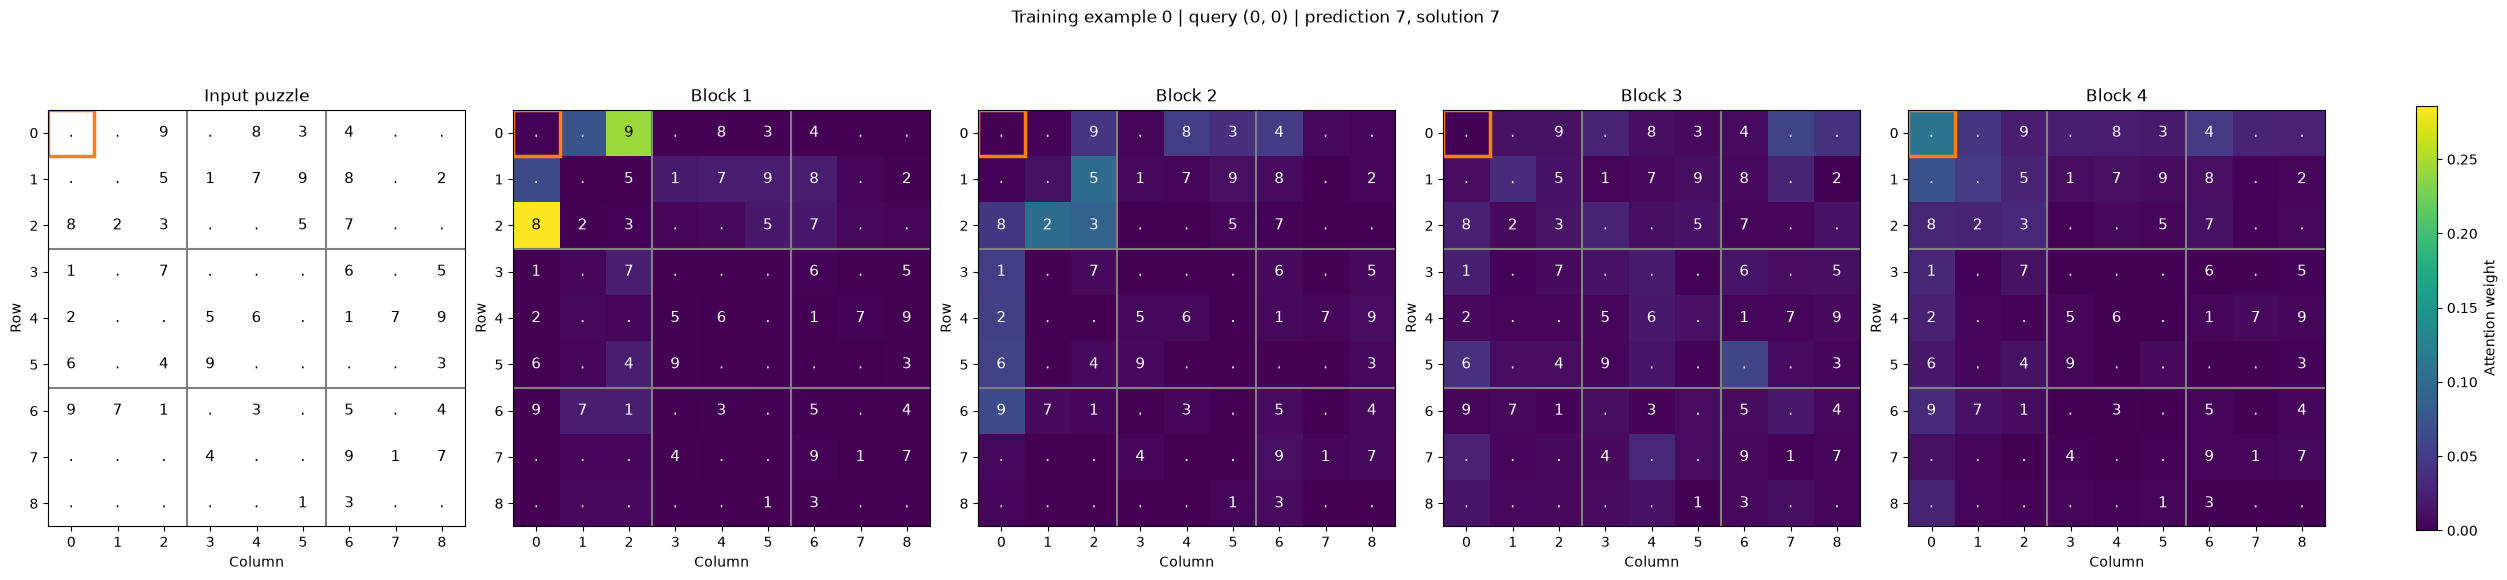

In [25]:

fig, axes = plt.subplots(
    1, len(net.blocks) + 1,
    figsize=(5 * (len(net.blocks) + 1), 6),
    layout='constrained',
)
vmax = weights.max().item()
for index, ax in enumerate(axes):
    if index == 0:
        ax.imshow(torch.ones(9, 9).numpy(), cmap='gray', vmin=0, vmax=1)
        ax.set_title('Input puzzle')
    else:
        image = ax.imshow(weights[index - 1].numpy(), cmap='viridis', vmin=0, vmax=vmax)
        ax.set_title(f'Block {index}')
    for r in range(9):
        for c in range(9):
            digit = puzzle[r, c].item()
            text_color = 'black' if index == 0 or weights[index - 1, r, c] > vmax * 0.55 else 'white'
            ax.text(c, r, str(digit) if digit else '.', ha='center', va='center', color=text_color, fontsize=11)
    for boundary in [2.5, 5.5]:
        ax.axhline(boundary, color='gray', linewidth=1.5)
        ax.axvline(boundary, color='gray', linewidth=1.5)
    ax.add_patch(Rectangle(
        (query_col - 0.5, query_row - 0.5), 1, 1,
        fill=False, edgecolor='#ff7f0e', linewidth=2.5,
    ))
    ax.set(xticks=range(9), yticks=range(9), xlabel='Column', ylabel='Row')
fig.colorbar(image, ax=axes[1:].tolist(), label='Attention weight', shrink=0.75)
predicted_digit = prediction[query_row, query_col].item()
true_digit = solution[query_row, query_col].item()
fig.suptitle(
    f'Training example {EXAMPLE_INDEX} | query ({query_row}, {query_col})'
    f' | prediction {predicted_digit}, solution {true_digit}'
)
plt.show()


Save the figure as a high-resolution PNG in the Sudoku directory.

In [26]:
output_path = SUDOKU_DIR / 'training_example_attention.png'
fig.savefig(output_path, dpi=300, bbox_inches='tight')
print(f'Saved {output_path}')


Saved /home/lucchi0001/work/Foundations_Deep_Learning_course_HS26/notebooks/01_MLP/Sudoku/training_example_attention.png
